In [ ]:
#ДЗ 3
# 1. Для изображения sar_3.jpg найти наиболее протяженный участок
# (выделить линии при помощи преобразования Хафа)
# 2. Для изображения sar_3.jpg провести исследование алгоритмов бинаризации, выделить участок дорожной полосы.

In [12]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

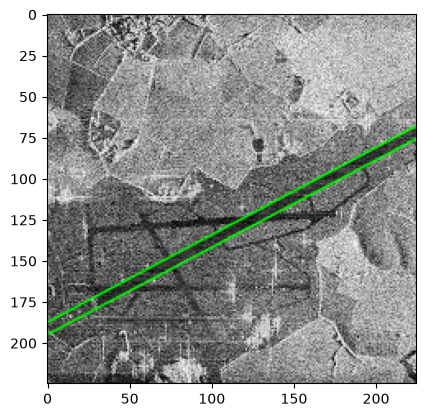

In [57]:
#1
image = cv2.imread('sar_3.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) 

canny = cv2.Canny(image_gray, 200, 400, apertureSize = 3)
lines = cv2.HoughLines(canny, 1, np.pi / 180, 100)

import math 

if lines is not None:
        for i in range(0, len(lines)):
            rho = lines[i][0][0]
            theta = lines[i][0][1]
            a = math.cos(theta)
            b = math.sin(theta)
            x0 = a * rho
            y0 = b * rho
            pt1 = (int(x0 + 1000*(-b)), int(y0 + 1000*(a)))
            pt2 = (int(x0 - 1000*(-b)), int(y0 - 1000*(a)))
            cv2.line(image, pt1, pt2, (0, 255, 0), 1, cv2.LINE_AA)
plt.imshow(image, cmap = 'gray')

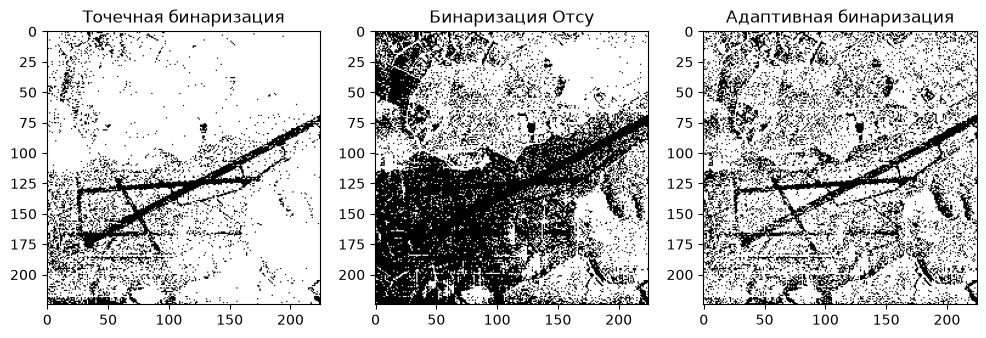

In [73]:
#2
import copy

plt.figure(figsize=(12, 4))

bin_img = copy.deepcopy(image_gray)
T  = 75
bin_img[image_gray < T] = 0
bin_img[image_gray >= T] = 255

plt.subplot(1, 3, 1)
plt.title("Точечная бинаризация")
plt.imshow(bin_img, cmap="gray")


_,th2 = cv2.threshold(image_gray,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)

plt.subplot(1, 3, 2)
plt.title("Бинаризация Отсу")
plt.imshow(th2, cmap="gray")


th3 = cv2.adaptiveThreshold(image_gray,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY,71,21)

plt.subplot(1, 3, 3)
plt.title("Адаптивная бинаризация")
plt.imshow(th3, cmap="gray")

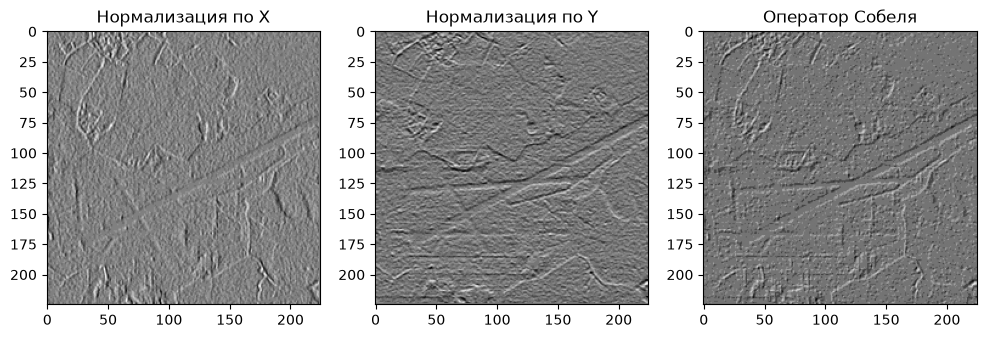

In [112]:
scale = 0.01
delta = 0
ddepth = cv2.CV_16S
grad_x = cv2.Sobel(image_gray, ddepth, 1, 0, ksize=3, scale=scale, delta=delta, borderType=cv2.BORDER_DEFAULT)
grad_y = cv2.Sobel(image_gray, ddepth, 0, 1, ksize=3, scale=scale, delta=delta, borderType=cv2.BORDER_DEFAULT)
grad = cv2.addWeighted(grad_x, 0.5, grad_y, 0.5, 0.0)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.title("Нормализация по X")
plt.imshow((grad_x - grad_x.min())*255, cmap="gray")

plt.subplot(1, 3, 2)
plt.title("Нормализация по Y")
plt.imshow((grad_y - grad_y.min())*255, cmap="gray")

plt.subplot(1, 3, 3)
plt.title("Оператор Собеля")
plt.imshow((grad - grad.min())*255, cmap="gray")